# 02 — Retail Sales Data Analysis

Explore Global Superstore sales by product, category, region, and month from 2011 through 2014.

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates

### Load the prepared sales CSV

In [2]:
from pathlib import Path

data_path = Path("data/retail_sales.csv")
if not data_path.is_file():
    raise FileNotFoundError(
        "Put the prepared CSV at data/retail_sales.csv and run from the project folder."
    )

df = pd.read_csv(data_path)
required_columns = {
    "Order ID", "Order Date", "Product ID", "Product Name", "Category",
    "Quantity", "Unit Price", "Region", "Customer ID",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {', '.join(sorted(missing_columns))}")

df = pd.read_csv("data/retail_sales.csv")

## 2. Inspect the data

### Preview the first and last five rows

In [3]:
print(df.head(5))

print()

print(df.tail(5))

          Order ID Order Date        Product ID                 Product Name  \
0     AG-2011-2040   1/1/2011  OFF-TEN-10000025          Tenex Lockers, Blue   
1    IN-2011-47883   1/1/2011   OFF-SU-10000618     Acme Trimmer, High Speed   
2     HU-2011-1220   1/1/2011  OFF-TEN-10001585      Tenex Box, Single Width   
3  IT-2011-3647632   1/1/2011   OFF-PA-10001492  Enermax Note Cards, Premium   
4    IN-2011-47883   1/1/2011   FUR-FU-10003447   Eldon Light Bulb, Duo Pack   

          Category  Quantity  Unit Price   Region Customer ID  
0  Office Supplies         2     204.150   Africa    TB-11280  
1  Office Supplies         3      40.122  Oceania    JH-15985  
2  Office Supplies         4      16.530     EMEA      AT-735  
3  Office Supplies         3      14.955    North    EM-14140  
4        Furniture         5      22.734  Oceania    JH-15985  

             Order ID  Order Date        Product ID  \
51285  CA-2014-115427  31-12-2014   OFF-BI-10002103   
51286    MO-2014-2560  3

### Check the shape, columns, and data types

In [4]:
print("Dimension:", df.shape)

print("Total Columns:", df.shape[1])

Dimension: (51290, 9)
Total Columns: 9


In [5]:
print("Columns: ", df.columns.tolist())

print("\nData Type:")
print(df.dtypes)

print("\nData Type Info: ")
df.info()

Columns:  ['Order ID', 'Order Date', 'Product ID', 'Product Name', 'Category', 'Quantity', 'Unit Price', 'Region', 'Customer ID']

Data Type:
Order ID            str
Order Date          str
Product ID          str
Product Name        str
Category            str
Quantity          int64
Unit Price      float64
Region              str
Customer ID         str
dtype: object

Data Type Info: 
<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order ID      51290 non-null  str    
 1   Order Date    51290 non-null  str    
 2   Product ID    51290 non-null  str    
 3   Product Name  51290 non-null  str    
 4   Category      51290 non-null  str    
 5   Quantity      51290 non-null  int64  
 6   Unit Price    51290 non-null  float64
 7   Region        51290 non-null  str    
 8   Customer ID   51290 non-null  str    
dtypes: float64(1), int64(1), str(7)
mem

### Summarize numeric and categorical columns

In [6]:
descriptive_summary = df.describe(include="all").T

print("Descriptive Statistics:")
display(descriptive_summary)

Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order ID,51290,25035,CA-2014-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,51290,1430,18-06-2014,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product ID,51290,10292,OFF-AR-10003651,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Name,51290,3788,Staples,227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,51290,3,Office Supplies,31273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,51290.0,NaN,NaN,NaN,3.476545,2.278766,1.0,2.0,3.0,5.0,14.0
Unit Price,51290.0,NaN,NaN,NaN,71.657487,113.581515,0.336,11.7999,29.4,82.16,3773.08
Region,51290,13,Central,11117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,51290,1590,PO-18850,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Count missing values and exact duplicate rows

In [7]:
print("Per Column Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values: ", df.isnull().sum().sum())

Per Column Missing Values:
Order ID        0
Order Date      0
Product ID      0
Product Name    0
Category        0
Quantity        0
Unit Price      0
Region          0
Customer ID     0
dtype: int64

Total Missing Values:  0


In [8]:
print("Total Duplicate Records:", df.duplicated().sum())

print("\n", df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))

Total Duplicate Records: 9

               Order ID  Order Date        Product ID  \
32830     AG-2014-4840  20-08-2014  TEC-MEM-10002524   
32840     AG-2014-4840  20-08-2014  TEC-MEM-10002524   
48047  ES-2012-2740636  29-08-2012   OFF-AR-10004884   
48055  ES-2012-2740636  29-08-2012   OFF-AR-10004884   
22520  ES-2013-2926991  14-06-2013   OFF-BI-10000179   
22523  ES-2013-2926991  14-06-2013   OFF-BI-10000179   
773      ID-2011-54176    3/5/2011   OFF-BI-10000168   
774      ID-2011-54176    3/5/2011   OFF-BI-10000168   
5203     IN-2012-38657   5/11/2012   FUR-CH-10002510   
5211     IN-2012-38657   5/11/2012   FUR-CH-10002510   
10094    IN-2013-66265    6/6/2013   OFF-AR-10003461   
10109    IN-2013-66265    6/6/2013   OFF-AR-10003461   
37162     KE-2013-2790  23-02-2013  OFF-CAM-10004002   
37164     KE-2013-2790  23-02-2013  OFF-CAM-10004002   
4529    MX-2012-137561   3/12/2012   FUR-CH-10000892   
4532    MX-2012-137561   3/12/2012   FUR-CH-10000892   
37267   US-2011-150

### Inspect and parse order dates

Use month/day/year for slash-separated dates and day-month-year for hyphen-separated dates. Check these conventions against the source.

In [9]:
print("Date Column Data Type:", df["Order Date"].dtype)

print("\nFirst ten dates:\n", df["Order Date"].head(10))

print("\nTen randomly selected dates:\n", df["Order Date"].sample(10, random_state=42))

print("\nSlash Format:\n", df["Order Date"].str.contains("/", na=False).sum())

print("\nHyphen Format:\n", df["Order Date"].str.contains("-", na=False).sum())

Date Column Data Type: str

First ten dates:
 0    1/1/2011
1    1/1/2011
2    1/1/2011
3    1/1/2011
4    1/1/2011
5    1/1/2011
6    1/2/2011
7    1/2/2011
8    1/2/2011
9    1/2/2011
Name: Order Date, dtype: str

Ten randomly selected dates:
 49728    30-09-2013
45547    27-12-2012
15664      5/6/2014
40561    25-03-2013
49426    30-06-2014
18956     11/4/2014
14238      3/1/2014
31818    19-12-2013
41388    25-09-2013
37236    23-03-2013
Name: Order Date, dtype: str

Slash Format:
 20067

Hyphen Format:
 31223


In [10]:
date_text = df["Order Date"].astype("string").str.strip()

slash_mask = date_text.str.contains("/", na=False)
hyphen_mask = date_text.str.contains("-", na=False)

parsed_dates = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")

parsed_dates.loc[slash_mask] = pd.to_datetime(
    date_text.loc[slash_mask], format="%m/%d/%Y", errors="coerce")

parsed_dates.loc[hyphen_mask] = pd.to_datetime(
    date_text.loc[hyphen_mask], format="%d-%m-%Y", errors="coerce")

print("Converted Date Data Type:", parsed_dates.dtype)
print("Invalid or Missing Converted Dates:", parsed_dates.isnull().sum())
print("Earliest Order Date:", parsed_dates.min())
print("Latest Order Date:", parsed_dates.max())
print("DataFrame Shape (unchanged):", df.shape)

if parsed_dates.isna().any():
    raise ValueError("Check unparsed Order Date values before calculating revenue.")

Converted Date Data Type: datetime64[ns]
Invalid or Missing Converted Dates: 0
Earliest Order Date: 2011-01-01 00:00:00
Latest Order Date: 2014-12-31 00:00:00
DataFrame Shape (unchanged): (51290, 9)


### Count rows by category and region

In [11]:
print("Unique Categories:\n", df["Category"].unique())
print("\nTotal Categories:", df["Category"].nunique())

print("\nCount records in each category:\n", df["Category"].value_counts())

print("\nUnique Sales Regions:\n", df["Region"].unique())

print("\nTotal Regions:\n", df["Region"].nunique())

print("\nCount records in each region:\n", df["Region"].value_counts())

Unique Categories:
 <StringArray>
['Office Supplies', 'Furniture', 'Technology']
Length: 3, dtype: str

Total Categories: 3

Count records in each category:
 Category
Office Supplies    31273
Technology         10141
Furniture           9876
Name: count, dtype: int64

Unique Sales Regions:
 <StringArray>
[        'Africa',        'Oceania',           'EMEA',          'North',
   'Central Asia',           'West',     'North Asia',        'Central',
          'South',         'Canada', 'Southeast Asia',           'East',
      'Caribbean']
Length: 13, dtype: str

Total Regions:
 13

Count records in each region:
 Region
Central           11117
South              6645
EMEA               5029
North              4785
Africa             4587
Oceania            3487
West               3203
Southeast Asia     3129
East               2848
North Asia         2338
Central Asia       2048
Caribbean          1690
Canada              384
Name: count, dtype: int64


### Check quantity and unit price ranges

In [12]:
print("Min/Max comparision:\n", df[["Quantity", "Unit Price"]].agg(["min", "max"]))

print("\nDetailed Statistics:\n", df[["Quantity", "Unit Price"]].describe())

Min/Max comparision:
      Quantity  Unit Price
min         1       0.336
max        14    3773.080

Detailed Statistics:
            Quantity    Unit Price
count  51290.000000  51290.000000
mean       3.476545     71.657487
std        2.278766    113.581515
min        1.000000      0.336000
25%        2.000000     11.799900
50%        3.000000     29.400000
75%        5.000000     82.160000
max       14.000000   3773.080000


**Inspection result** — 51,290 rows, nine columns, no missing values, and nine repeat rows.

## 3. Clean the data

Work on a copy of the input.

In [13]:
df_clean = df.copy()

print("Original df shape:", df.shape)
print("df_clean shape:", df_clean.shape)
print("Same shape:", df.shape == df_clean.shape)
print("Same object?:", df is df_clean)

Original df shape: (51290, 9)
df_clean shape: (51290, 9)
Same shape: True
Same object?: False


### Remove exact repeat rows

Keep distinct product lines within the same order.

In [14]:
print("Rows before:", len(df_clean))
print("Duplicate rows:", df_clean.duplicated().sum())

Rows before: 51290
Duplicate rows: 9


In [15]:
df_clean = df_clean.drop_duplicates()

print("Rows after:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Rows after: 51281
Rows removed: 9
Remaining duplicate rows: 0


### Assign the parsed dates

In [16]:
df_clean["Order Date"]  = parsed_dates.loc[df_clean.index]

print("Order Data dtype:", df_clean["Order Date"].dtype)
print("Missing dates:", df_clean["Order Date"].isnull().sum())
print("Earliest:", df_clean["Order Date"].min())
print("Latest:", df_clean["Order Date"].max())

Order Data dtype: datetime64[ns]
Missing dates: 0
Earliest: 2011-01-01 00:00:00
Latest: 2014-12-31 00:00:00


### Check the cleaned data

In [17]:
validation = pd.DataFrame({
    "Check": [
        "Total rows",
        "Total columns",
        "Missing values",
        "Duplicate rows",
        "Date data type",
        "Earliest date",
        "Latest date",
    ],
    "Expected": [
        51281, 9, 0, 0, "datetime64[ns]", "2011-01-01", "2014-12-31",
    ],
    "Actual": [
        df_clean.shape[0],
        df_clean.shape[1],
        int(df_clean.isnull().sum().sum()),
        int(df_clean.duplicated().sum()),
        str(df_clean["Order Date"].dtype),
        df_clean["Order Date"].min().strftime("%Y-%m-%d"),
        df_clean["Order Date"].max().strftime("%Y-%m-%d"),
    ],
})

validation["Pass"] = validation["Expected"].astype(str) == validation["Actual"].astype(str)
validation

,Check,Expected,Actual,Pass
0,Total rows,51281,51281,True
1,Total columns,9,9,True
2,Missing values,0,0,True
3,Duplicate rows,0,0,True
4,Date data type,datetime64[ns],datetime64[ns],True
5,Earliest date,2011-01-01,2011-01-01,True
6,Latest date,2014-12-31,2014-12-31,True


In [18]:
print("Original df rows:", len(df))
print("Original df columns:", df.shape[1])
print("Original columns:", list(df.columns))
print("Original Order Date dtype:", df["Order Date"].dtype)
print("Same columns as df_clean:", list(df.columns) == list(df_clean.columns))

Original df rows: 51290
Original df columns: 9
Original columns: ['Order ID', 'Order Date', 'Product ID', 'Product Name', 'Category', 'Quantity', 'Unit Price', 'Region', 'Customer ID']
Original Order Date dtype: str
Same columns as df_clean: True


**Cleaning result** — 51,281 rows spanning January 2011 through December 2014.

## 4. Analyze sales

### Calculate line revenue

Multiply quantity by unit price.

In [19]:
revenue = df_clean["Quantity"] * df_clean["Unit Price"]

df_clean["Revenue"] = revenue

print("Updated dataset:\n", df_clean.head())

Updated dataset:
           Order ID Order Date        Product ID                 Product Name  \
0     AG-2011-2040 2011-01-01  OFF-TEN-10000025          Tenex Lockers, Blue   
1    IN-2011-47883 2011-01-01   OFF-SU-10000618     Acme Trimmer, High Speed   
2     HU-2011-1220 2011-01-01  OFF-TEN-10001585      Tenex Box, Single Width   
3  IT-2011-3647632 2011-01-01   OFF-PA-10001492  Enermax Note Cards, Premium   
4    IN-2011-47883 2011-01-01   FUR-FU-10003447   Eldon Light Bulb, Duo Pack   

          Category  Quantity  Unit Price   Region Customer ID  Revenue  
0  Office Supplies         2     204.150   Africa    TB-11280  408.300  
1  Office Supplies         3      40.122  Oceania    JH-15985  120.366  
2  Office Supplies         4      16.530     EMEA      AT-735   66.120  
3  Office Supplies         3      14.955    North    EM-14140   44.865  
4        Furniture         5      22.734  Oceania    JH-15985  113.670  


In [20]:
print("df_clean shape :", df_clean.shape)
print("df shape :", df.shape)

df_clean shape : (51281, 10)
df shape : (51290, 9)


In [21]:
print(df_clean["Revenue"].describe().round(2))

count    51281.00
mean       246.51
std        487.60
min          0.44
25%         30.77
50%         85.06
75%        251.01
max      22638.48
Name: Revenue, dtype: float64


### Check the calculated revenue

In [22]:
print("Revenue in df? :", "Revenue" in df.columns)
print("Revenue dtype  :", df_clean["Revenue"].dtype)
print("Missing Revenue:", df_clean["Revenue"].isnull().sum())
print("Negative Revenue rows:", (df_clean["Revenue"] < 0).sum())
print("Zero Revenue rows:", (df_clean["Revenue"] == 0).sum())
print("Minimum Revenue:", df_clean["Revenue"].min())
print("Maximum Revenue:", df_clean["Revenue"].max())

Revenue in df? : False
Revenue dtype  : float64
Missing Revenue: 0
Negative Revenue rows: 0
Zero Revenue rows: 0
Minimum Revenue: 0.444
Maximum Revenue: 22638.48


In [23]:
sample = df_clean[["Quantity", "Unit Price", "Revenue"]].sample(5, random_state=42)
sample["Manual Check"] = sample["Quantity"] * sample["Unit Price"]
sample["Match"] = sample["Revenue"] == sample["Manual Check"]
sample

,Quantity,Unit Price,Revenue,Manual Check,Match
13806,3,183.360,550.080,550.080,True
9770,6,18.990,113.940,113.940,True
23191,3,76.480,229.440,229.440,True
48725,4,15.378,61.512,61.512,True
38043,2,370.926,741.852,741.852,True


### Summarize sales and average order value

Sum line revenue within each order, then average the order totals.

### Filter sales

Try a category, a region, and an inclusive date range separately and together.

In [24]:
category = "Technology"
region = "Central"
start_date = "2014-01-01"
end_date = "2014-12-31"

by_category = df_clean.loc[df_clean["Category"].eq(category)]
by_region = df_clean.loc[df_clean["Region"].eq(region)]
by_date = df_clean.loc[df_clean["Order Date"].between(start_date, end_date)]
combined = by_date.loc[by_date["Category"].eq(category) & by_date["Region"].eq(region)]

for label, sales in [
    ("Category", by_category),
    ("Region", by_region),
    ("Date range", by_date),
    ("Combined", combined),
]:
    print(f"{label}: {len(sales):,} rows")
display(combined.head())

Category: 10,140 rows
Region: 11,116 rows
Date range: 17,530 rows
Combined: 718 rows


,Order ID,Order Date,Product ID,Product Name,Category,Quantity,Unit Price,Region,Customer ID,Revenue
13206,ES-2014-2774938,2014-01-01,TEC-MA-10001777,"Okidata Printer, Red",Technology,3,225.80250,Central,FH-14350,677.40750
13208,IT-2014-4810734,2014-01-01,TEC-PH-10002586,"Nokia Office Telephone, with Caller ID",Technology,6,55.36050,Central,AS-10240,332.16300
13237,US-2014-116778,2014-01-03,TEC-CO-10000388,"Canon Fax Machine, Color",Technology,3,127.50556,Central,JS-16030,382.51668
13253,ES-2014-4064307,2014-01-04,TEC-MA-10000331,"Okidata Printer, White",Technology,8,266.91000,Central,CC-12370,2135.28000
13255,ES-2014-3900205,2014-01-04,TEC-PH-10000292,"Samsung Office Telephone, Full Size",Technology,5,33.25500,Central,ME-17725,166.27500


In [25]:
print(f"Total Revenue: {df_clean['Revenue'].sum():,.2f}")
print(f"Total Quantity Sold: {df_clean['Quantity'].sum():,}")
print(f"Unique Orders: {df_clean['Order ID'].nunique():,}")
print(f"Unique Customers: {df_clean['Customer ID'].nunique():,}")
print(f"Unique Products: {df_clean['Product ID'].nunique():,}")

order_totals = df_clean.groupby("Order ID")["Revenue"].sum()
aov = order_totals.mean()

print(f"Average Order Value (AOV): {aov:,.2f}")

Total Revenue: 12,641,024.34
Total Quantity Sold: 178,290
Unique Orders: 25,035
Unique Customers: 1,590
Unique Products: 10,292
Average Order Value (AOV): 504.93


In [26]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue", "Total Quantity Sold", "Unique Orders",
        "Unique Customers", "Unique Products", "Average Order Value",
    ],
    "Value": [
        round(df_clean["Revenue"].sum(), 2), int(df_clean["Quantity"].sum()), df_clean["Order ID"].nunique(),
        df_clean["Customer ID"].nunique(), df_clean["Product ID"].nunique(), round(aov, 2),
    ],
})
kpi_summary

,Metric,Value
0,Total Revenue,12641024.34
1,Total Quantity Sold,178290.00
2,Unique Orders,25035.00
3,Unique Customers,1590.00
4,Unique Products,10292.00
5,Average Order Value,504.93


### Compare revenue and units by category

In [27]:
print(df_clean["Category"].unique())

<StringArray>
['Office Supplies', 'Furniture', 'Technology']
Length: 3, dtype: str


In [28]:
category_summary = (
    df_clean.groupby("Category")[["Revenue", "Quantity"]].sum().sort_values("Revenue", ascending=False)
)

category_summary

,Revenue,Quantity
Category,,
Technology,4.744501e+06,35174
Furniture,4.109634e+06,34945
Office Supplies,3.786890e+06,108171


In [29]:
top_category = category_summary["Revenue"].idxmax()
bottom_category = category_summary["Revenue"].idxmin()

print(f"Highest-revenue category: {top_category} "
      f"({category_summary.loc[top_category, 'Revenue']:,.2f})")
print(f"Lowest-revenue category : {bottom_category} "
      f"({category_summary.loc[bottom_category, 'Revenue']:,.2f})")

Highest-revenue category: Technology (4,744,500.74)
Lowest-revenue category : Office Supplies (3,786,889.86)


### Compare revenue and units by region

In [30]:
region_summary = (
    df_clean.groupby("Region")[["Revenue", "Quantity"]].sum().sort_values("Revenue", ascending=False)
)

region_summary

,Revenue,Quantity
Region,,
Central,2.822265e+06,41759
South,1.600208e+06,25201
North,1.248166e+06,18021
Oceania,1.100146e+06,12834
Southeast Asia,8.840793e+05,11817
North Asia,8.483098e+05,8851
EMEA,8.061613e+05,11517
Africa,7.836960e+05,10561
Central Asia,7.528266e+05,7715


In [31]:
top_region = region_summary["Revenue"].head(3)
bottom_region = region_summary["Revenue"].tail(3)

print("Top three regions:\n", top_region)
print("\nBottom three regions:", bottom_region)

Top three regions:
 Region
Central    2.822265e+06
South      1.600208e+06
North      1.248166e+06
Name: Revenue, dtype: float64

Bottom three regions: Region
East         678499.86800
Caribbean    324280.86104
Canada        66928.17000
Name: Revenue, dtype: float64


### Group sales by Product ID

Use the most frequent name as the display label when one ID has multiple names.

In [32]:
product_name_counts = (
    df_clean.groupby("Product ID")["Product Name"]
    .nunique()
    .sort_values(ascending=False)
)

inconsistent_products = product_name_counts[
    product_name_counts > 1
]

print("Total unique Product IDs:", df_clean["Product ID"].nunique())
print("Product IDs with multiple names:", len(inconsistent_products))

display(inconsistent_products)

Total unique Product IDs: 10292
Product IDs with multiple names: 457


Product ID
OFF-PA-10004673    4
OFF-SU-10003629    3
FUR-FU-10004960    3
TEC-AC-10003063    3
OFF-BI-10004632    3
                  ..
TEC-CO-10001818    2
FUR-FU-10003664    2
FUR-BO-10000895    2
OFF-SU-10003343    2
FUR-FU-10001473    2
Name: Product Name, Length: 457, dtype: int64

In [33]:
inconsistent_ids = inconsistent_products.index

inconsistent_records = (
    df_clean[df_clean["Product ID"].isin(inconsistent_ids)]
    .sort_values("Product ID")
)

display(
    inconsistent_records[
        ["Product ID", "Product Name", "Category", "Revenue", "Quantity"]
    ]
)

,Product ID,Product Name,Category,Revenue,Quantity
4848,FUR-BO-10000087,"Sauder Corner Shelving, Pine",Furniture,198.200,2
9166,FUR-BO-10000087,"Sauder Corner Shelving, Pine",Furniture,297.300,3
13837,FUR-BO-10000087,"Sauder Corner Shelving, Pine",Furniture,79.280,1
30157,FUR-BO-10000087,"Sauder Corner Shelving, Pine",Furniture,297.300,5
4684,FUR-BO-10000087,"Dania Classic Bookcase, Mobile",Furniture,826.560,2
...,...,...,...,...,...
50554,TEC-PH-10004959,"Motorola Audio Dock, with Caller ID",Technology,346.740,4
33751,TEC-PH-10004959,"Motorola Audio Dock, with Caller ID",Technology,346.740,2
877,TEC-PH-10004959,"Motorola Audio Dock, with Caller ID",Technology,780.165,5
17965,TEC-PH-10004959,"Motorola Audio Dock, with Caller ID",Technology,520.110,3


In [34]:
product_consistency = (
    df_clean.groupby("Product ID")
    .agg(
        Name_Count=("Product Name", "nunique"),
        Product_Names=("Product Name", lambda x: list(x.unique())),
        Category_Count=("Category", "nunique"),
        Categories=("Category", lambda x: list(x.unique()))
    )
    .reset_index()
)

inconsistent_summary = product_consistency[
    product_consistency["Name_Count"] > 1
].sort_values(
    ["Category_Count", "Name_Count"],
    ascending=False
)

display(inconsistent_summary.head(20))

,Product ID,Name_Count,Product_Names,Category_Count,Categories
6631,OFF-PA-10004673,4,"[Enermax Message Books, 8.5 x 11, Green Bar Me...",1,[Office Supplies]
243,FUR-BO-10002204,3,"[Dania Floating Shelf Set, Traditional, Bush C...",1,[Furniture]
749,FUR-CH-10002335,3,"[Hon Steel Folding Chair, Red, Hon GuestStacke...",1,[Furniture]
1333,FUR-FU-10001933,3,"[Tenex Stacking Tray, Black, Deflect-O Door St...",1,[Furniture]
1658,FUR-FU-10004960,3,"[Deflect-O Photo Frame, Duo Pack, Seth Thomas ...",1,[Furniture]
2900,OFF-AR-10000833,3,"[Binney & Smith Pencil Sharpener, Water Color,...",1,[Office Supplies]
3216,OFF-AR-10003651,3,"[Sanford Pens, Easy-Erase, Newell 350, Sanford...",1,[Office Supplies]
3242,OFF-AR-10003829,3,"[Stanley Markers, Fluorescent, Boston Highligh...",1,[Office Supplies]
3736,OFF-BI-10002799,3,"[Cardinal Binder Covers, Clear, SlimView Poly ...",1,[Office Supplies]
3847,OFF-BI-10003708,3,"[Avery Binder, Economy, Acco Four Pocket Poly ...",1,[Office Supplies]


In [35]:
print(
    "Product IDs with multiple names:",
    len(inconsistent_summary)
)

print(
    "Product IDs with multiple categories:",
    (product_consistency["Category_Count"] > 1).sum()
)

print(
    "Maximum number of names for one Product ID:",
    inconsistent_summary["Name_Count"].max()
)

Product IDs with multiple names: 457
Product IDs with multiple categories: 0
Maximum number of names for one Product ID: 4


In [36]:
top_selling = (
    df_clean.groupby("Product ID")
    .agg(
        Product_Name=("Product Name", lambda x: x.mode().iloc[0]),
        Category=("Category", "first"),
        Revenue=("Revenue", "sum"),
        Quantity=("Quantity", "sum")
    )
    .reset_index()
)


product_revenue = top_selling.sort_values("Revenue", ascending=False)
display(product_revenue.head(10))

,Product ID,Product_Name,Category,Revenue,Quantity
8969,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,61599.8240,20
10157,TEC-PH-10004664,"Nokia Smart Phone, with Caller ID",Technology,30041.5482,52
3825,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.3840,31
9294,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.4800,6
10171,TEC-PH-10004823,"Nokia Smart Phone, Full Size",Technology,22262.1000,39
708,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,21870.5760,39
518,FUR-CH-10000027,"SAFCO Executive Leather Armchair, Black",Furniture,21329.7300,50
2752,OFF-AP-10004512,"Hoover Stove, Red",Office Supplies,21147.0840,38
2008,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,20730.7557,48
3568,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,19823.4790,37


In [37]:
print("Rows in product summary:", len(top_selling))
print("Unique Product IDs:", top_selling["Product ID"].nunique())
print("Missing product names:", top_selling["Product_Name"].isna().sum())
print("Missing categories:", top_selling["Category"].isna().sum())
print("Total revenue:", round(top_selling["Revenue"].sum(), 2))
print("Total quantity:", top_selling["Quantity"].sum())

Rows in product summary: 10292
Unique Product IDs: 10292
Missing product names: 0
Missing categories: 0
Total revenue: 12641024.34
Total quantity: 178290


## 5. Visualize sales

### Set chart styles and number formatting

In [38]:
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [39]:
def thousands(x, pos):
    return f"{x:,.0f}"

money_fmt = FuncFormatter(thousands)

### Revenue by category

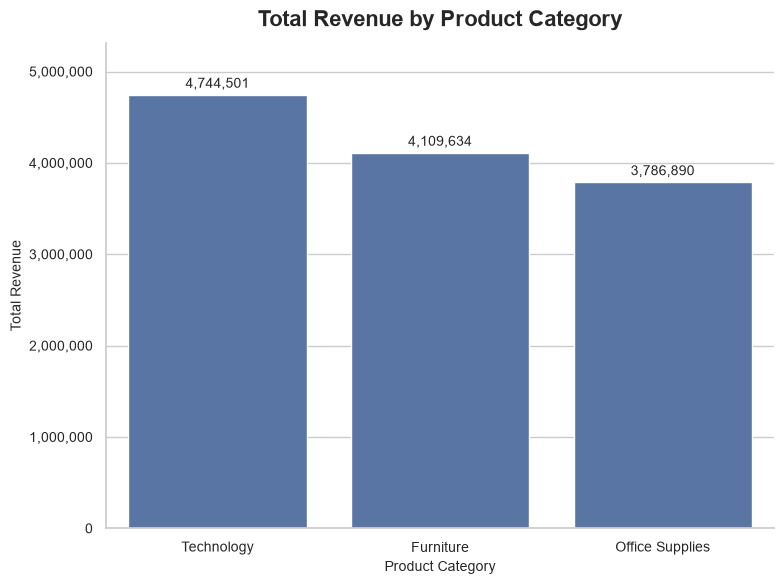

In [40]:
cat_plot = category_summary.reset_index()

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=cat_plot, x="Category", y="Revenue", ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=10)

ax.set_title("Total Revenue by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Total Revenue")
ax.yaxis.set_major_formatter(money_fmt)
ax.set_ylim(0, cat_plot["Revenue"].max() * 1.12)
plt.tight_layout()
plt.show()

### Revenue by region

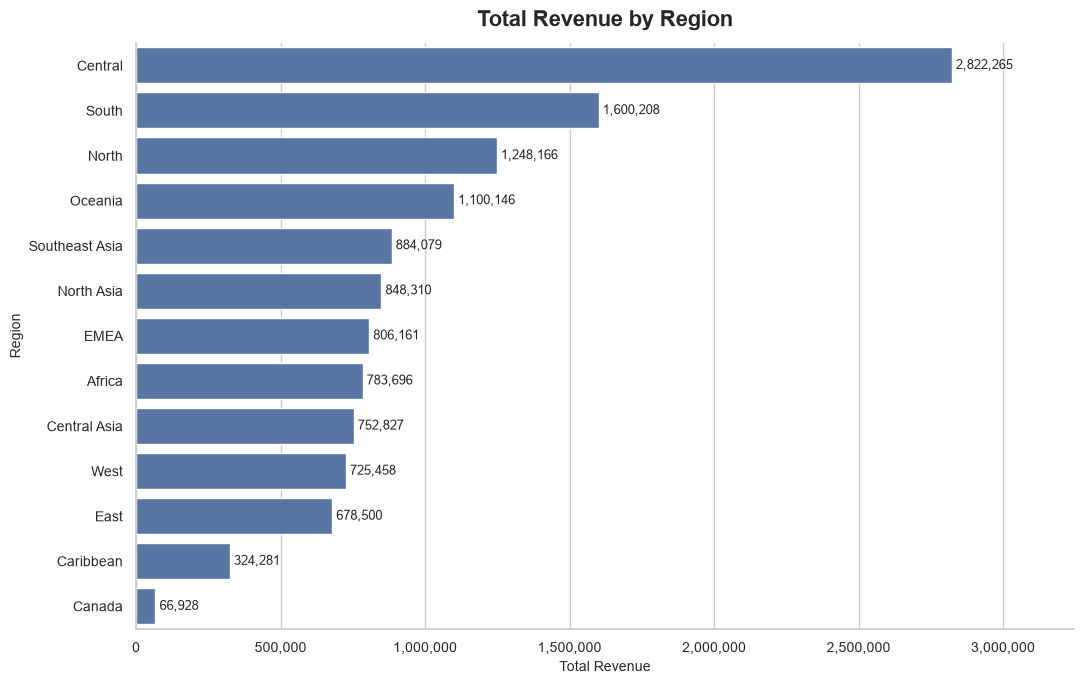

In [41]:
region_plot = region_summary.reset_index()

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(data=region_plot, x="Revenue", y="Region", ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)

ax.set_title("Total Revenue by Region")
ax.set_xlabel("Total Revenue")
ax.set_ylabel("Region")

ax.xaxis.set_major_formatter(money_fmt)
ax.set_xlim(0, region_plot["Revenue"].max() * 1.15)

plt.tight_layout()
plt.show()

### Top 10 products by revenue and by units sold

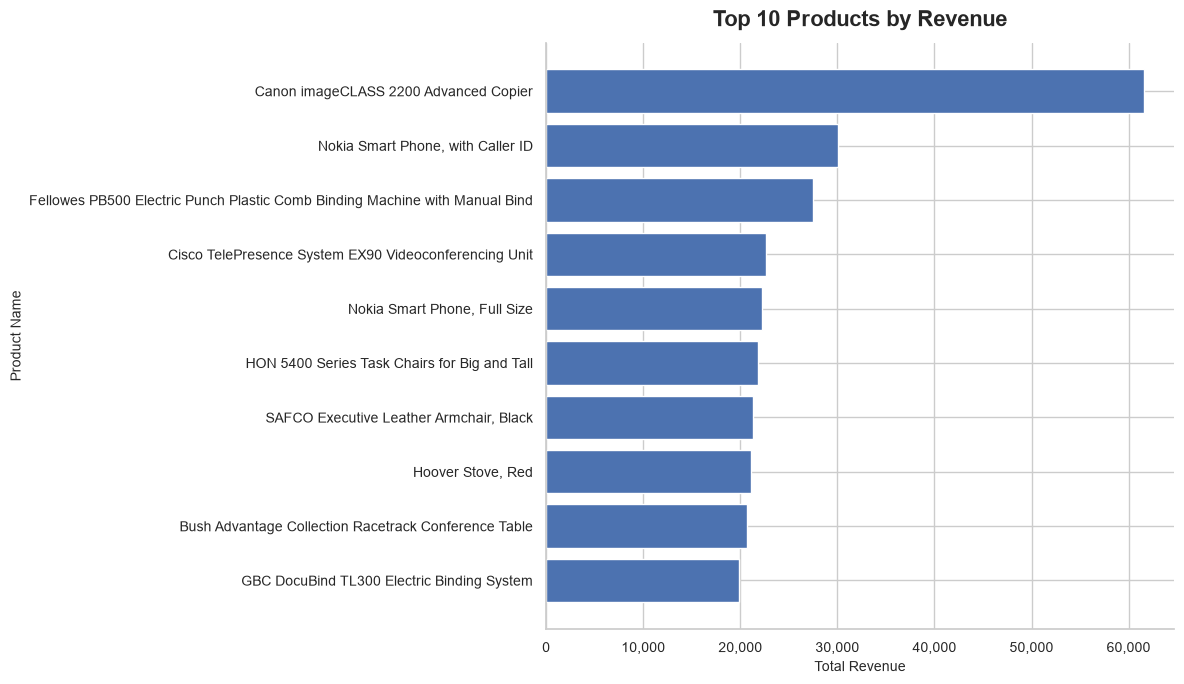

,Product ID,Product_Name,Category,Revenue,Quantity
8969,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,61599.8240,20
10157,TEC-PH-10004664,"Nokia Smart Phone, with Caller ID",Technology,30041.5482,52
3825,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.3840,31
9294,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.4800,6
10171,TEC-PH-10004823,"Nokia Smart Phone, Full Size",Technology,22262.1000,39
708,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,21870.5760,39
518,FUR-CH-10000027,"SAFCO Executive Leather Armchair, Black",Furniture,21329.7300,50
2752,OFF-AP-10004512,"Hoover Stove, Red",Office Supplies,21147.0840,38
2008,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,20730.7557,48
3568,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,19823.4790,37


In [42]:
top_10_revenue = (
    top_selling.nlargest(10, "Revenue").sort_values("Revenue", ascending=True)
)

plt.figure(figsize=(12, 7))

plt.barh(top_10_revenue["Product_Name"], top_10_revenue["Revenue"])

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Name")

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

display(
    top_10_revenue[
        ["Product ID", "Product_Name", "Category", "Revenue", "Quantity"]
    ].sort_values("Revenue", ascending=False)
)

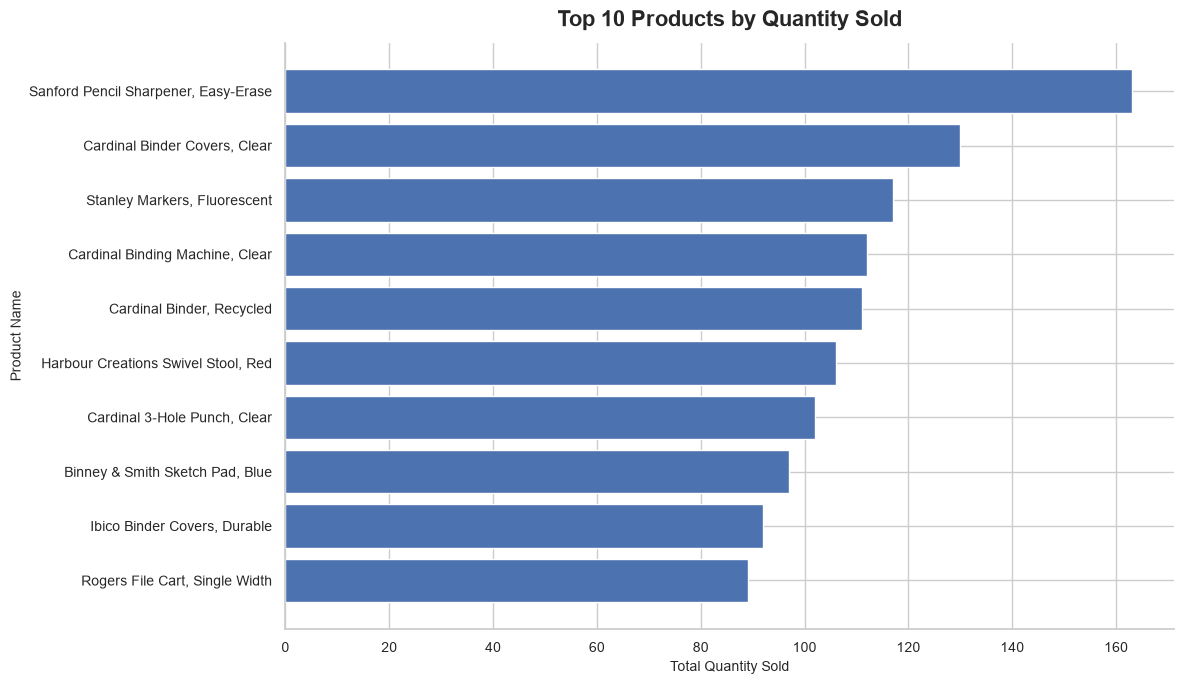

,Product ID,Product_Name,Category,Quantity,Revenue
3216,OFF-AR-10003651,"Sanford Pencil Sharpener, Easy-Erase",Office Supplies,163,2880.1300
3736,OFF-BI-10002799,"Cardinal Binder Covers, Clear",Office Supplies,130,984.0100
3242,OFF-AR-10003829,"Stanley Markers, Fluorescent",Office Supplies,117,1728.1220
3622,OFF-BI-10001808,"Cardinal Binding Machine, Clear",Office Supplies,112,4346.3745
3847,OFF-BI-10003708,"Cardinal Binder, Recycled",Office Supplies,111,1186.4300
844,FUR-CH-10003354,"Harbour Creations Swivel Stool, Red",Furniture,106,8184.5901
3709,OFF-BI-10002570,"Cardinal 3-Hole Punch, Clear",Office Supplies,102,1966.3560
2800,OFF-AR-10000110,"Binney & Smith Sketch Pad, Blue",Office Supplies,97,3900.1440
3915,OFF-BI-10004195,"Ibico Binder Covers, Durable",Office Supplies,92,2839.0500
7256,OFF-ST-10004377,"Rogers File Cart, Single Width",Office Supplies,89,10409.8050


In [43]:
top_10_quantity = (
    top_selling.nlargest(10, "Quantity").sort_values("Quantity", ascending=True)
)

plt.figure(figsize=(12, 7))

plt.barh(top_10_quantity["Product_Name"], top_10_quantity["Quantity"])

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

display(
    top_10_quantity[
        ["Product ID", "Product_Name", "Category", "Quantity", "Revenue"]
    ].sort_values("Quantity", ascending=False)
)

### Monthly revenue and peak month

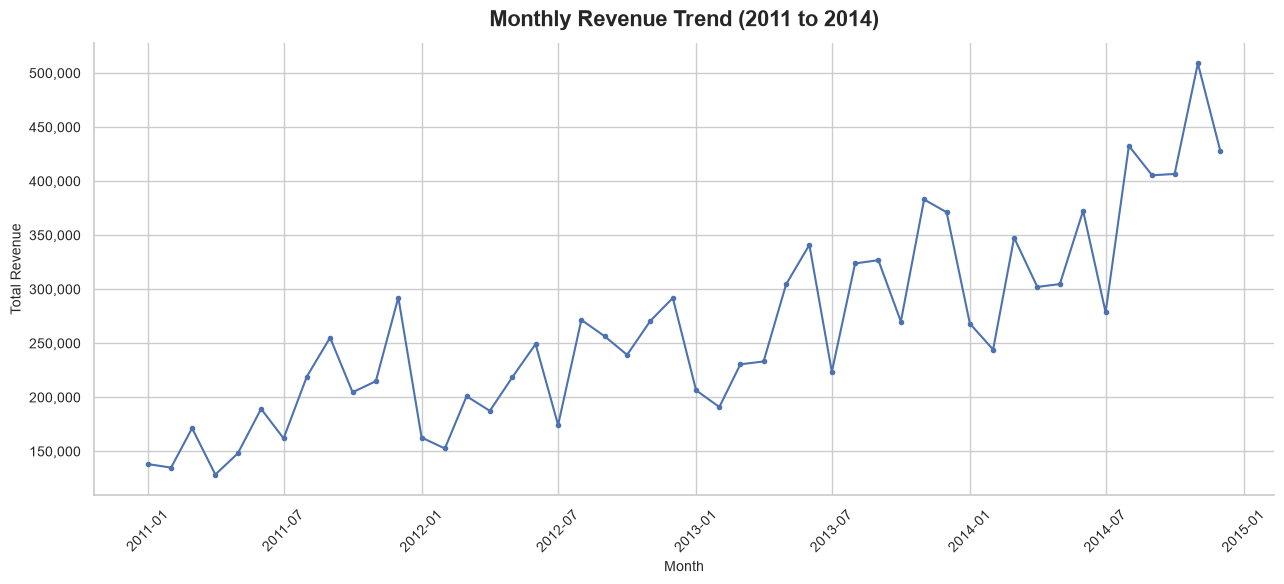

Total monthly observations: 48
Highest revenue month: 2014-11-01 00:00:00
Highest monthly revenue: 508954.73
Lowest revenue month: 2011-04-01 00:00:00
Lowest monthly revenue: 128552.1


In [44]:
monthly_revenue = (
    df_clean.set_index("Order Date")["Revenue"].resample("MS").sum()
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(monthly_revenue.index, monthly_revenue.values, marker="o", markersize=3, linewidth=1.5)

ax.set_title("Monthly Revenue Trend (2011 to 2014)")
ax.set_xlabel("Month")
ax.set_ylabel("Total Revenue")

ax.yaxis.set_major_formatter(money_fmt)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Total monthly observations:", len(monthly_revenue))
print("Highest revenue month:", monthly_revenue.idxmax())
print("Highest monthly revenue:", round(monthly_revenue.max(), 2))
print("Lowest revenue month:", monthly_revenue.idxmin())
print("Lowest monthly revenue:", round(monthly_revenue.min(), 2))

### Category share of revenue

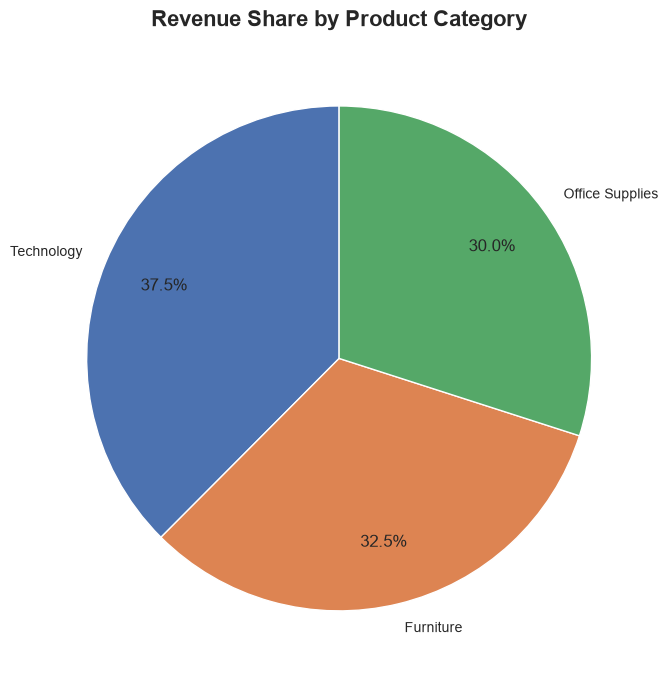

In [45]:
category_revenue = category_summary["Revenue"]

plt.figure(figsize=(8, 7))

plt.pie(category_revenue.values, labels=category_revenue.index, autopct="%1.1f%%", startangle=90, pctdistance=0.75)

plt.title("Revenue Share by Product Category")
plt.tight_layout()
plt.show()

### Units sold and revenue by product

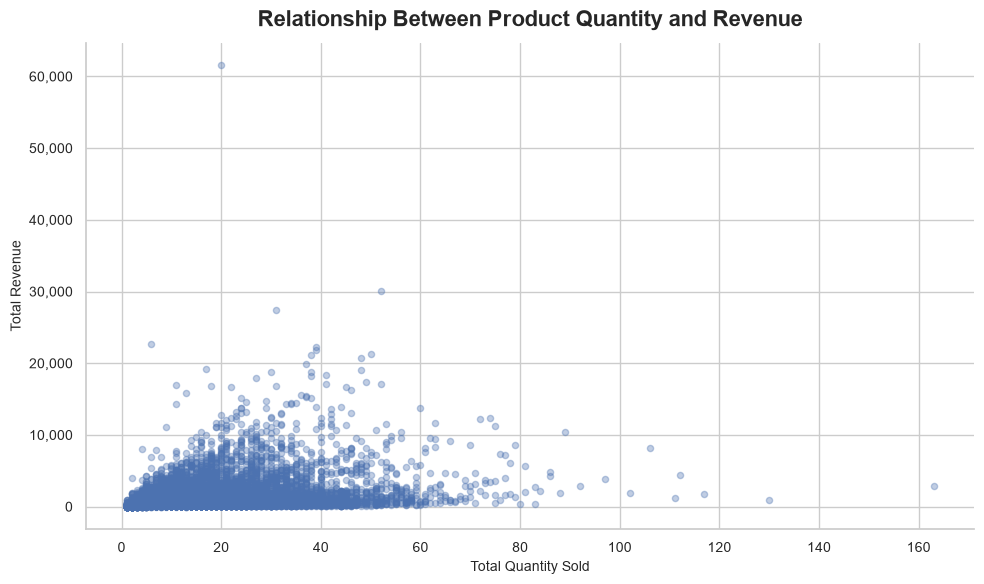

Correlation: 0.3


In [46]:
plt.figure(figsize=(10, 6))

plt.scatter(top_selling["Quantity"], top_selling["Revenue"], alpha=0.35, s=20)

plt.title("Relationship Between Product Quantity and Revenue")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Total Revenue")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

plt.tight_layout()
plt.show()

correlation = top_selling["Quantity"].corr(top_selling["Revenue"])

print("Correlation:", round(correlation, 2))

## 6. Findings

Technology led in revenue, Office Supplies sold the most units, and Central led regional revenue. November 2014 was the highest-revenue month at 508,954.73.

### Limitations

The analysis uses derived revenue from a historical dataset. Unit price provenance and currency should be documented. Costs are unavailable, so profitability is outside the scope.

In [47]:
final_project_summary = pd.DataFrame({
    "Metric": [
        "Original Records",
        "Cleaned Records",
        "Total Revenue",
        "Total Quantity Sold",
        "Unique Orders",
        "Unique Customers",
        "Unique Products",
        "Average Order Value"
    ],
    "Value": [
        len(df),
        len(df_clean),
        round(df_clean["Revenue"].sum(), 2),
        df_clean["Quantity"].sum(),
        df_clean["Order ID"].nunique(),
        df_clean["Customer ID"].nunique(),
        df_clean["Product ID"].nunique(),
        round(aov, 2)
    ]
})

display(final_project_summary)

,Metric,Value
0,Original Records,51290.00
1,Cleaned Records,51281.00
2,Total Revenue,12641024.34
3,Total Quantity Sold,178290.00
4,Unique Orders,25035.00
5,Unique Customers,1590.00
6,Unique Products,10292.00
7,Average Order Value,504.93
